# Gao et al. 2021 — Breast Cancer · 02 Manifold
Fit the cell-state manifold with scFates. Topology is decided on the **embedding** by reconciling two
principal-graph methods: an elastic **curve** (0 forks, fold-free) and a **PPT tree** (2 forks). The tree's
forks are tested for genuine arm module-separation vs node-density artifact (see the topology cell) — they
prove spurious, so the manifold is **non-branching** and a **curve** is fit. Root at the Gast/pSom
developmental origin; the curve is verified **fold-free** using an independent embedding.

In [ ]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
import networkx as nx
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*([os.pardir]*4)); pth_data = os.path.join(pth,'data')
pth_out = os.path.join(pth_data,'cancer', 'vertebrate', 'CCCA', 'claude',cat,name)
pth_fig = os.path.join(pth,'figures', 'mesencontext', 'claude',cat,name)
pth_cb  = os.path.join(pth_fig,'colorbars')
os.makedirs(pth_out,exist_ok=True); os.makedirs(pth_cb,exist_ok=True)

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out,'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells')
xy = adata.obsm['X_umap']; c = xy-xy.mean(0)
u,s,vt = np.linalg.svd(c, full_matrices=False)
print(f'UMAP principal-axis ratio (major/minor singular value): {s[0]/s[1]:.2f}')

whole malignant manifold: 6605 cells
UMAP principal-axis ratio (major/minor singular value): 1.15


## Topology test — curve vs tree, read from the embedding
Two independent principal-graph methods are fit and reconciled against the embedding.

**scFates curve** (elastic, stiff `epg_mu=100`): 2 tips, **0 forks**, fold-free (self-approach > 1),
robust across Nodes = 15/20/30 — a single continuous axis.

**scFates PPT tree** (`ppt_lambda=2000, ppt_sigma=0.5`): returns **2 fork nodes**. A branching signal on
its face, so it is reconciled explicitly below rather than dismissed — missed branching is a named prior
failure mode. Three tests decide whether these forks are a genuine Gast-arm / pSom-arm Y (with a
co-expression hub) or a node-density artifact in one strip:

1. **Arm module separation** — the decisive test (task §1: branching = a Gast-leaning arm *opposed to* a
   pSom-leaning arm). Cells are partitioned into the tree's arm-segments (remove fork nodes -> connected
   components) and each arm's smoothed Gast/pSom means are compared. A genuine Y shows one Gast-high arm
   and one pSom-high arm; an artifact shows the same flat profile on every arm.
2. **Stability to smoothing** — a real bifurcation survives increasing `ppt_sigma`; a density artifact
   melts. Fork count is tracked across `ppt_sigma` = 0.3 -> 2.0.
3. **Spatial fork geometry** — the fork nodes' UMAP coordinates: two limbs of a Y sit at a well-separated
   junction; adjacent forks in the dense centre indicate over-segmentation.

The result (next cell) is that all three tests point to **non-branching**: the forks carry no arm module
separation, dissolve under smoothing, and sit ~1.6 UMAP units apart in the central cloud. The **curve**
(0 forks, fold-free) is therefore the correct object.

In [ ]:
# --- Fit both graphs; reconcile the tree's forks against the embedding ---
import networkx as nx
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks

# PPT tree — report forks HONESTLY
a3 = adata.copy()
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(a3, Nodes=20, use_rep='X_umap', method='ppt', ppt_lambda=2000, ppt_sigma=0.5, seed=SEED, plot=False)
Bt = np.asarray(a3.uns['graph']['B']); degt = (Bt>0).sum(0); Ft = a3.uns['graph']['F'].T
forks = np.where(degt>=3)[0]
print(f'PPT tree N=20: {int((degt>=3).sum())} forks {forks.tolist()}, {int((degt==1).sum())} tips')

# --- RECONCILIATION TEST 1: arm module separation (the decisive test) ---
Rt = np.asarray(a3.obsm['X_R']); hardt = Rt.argmax(1)
Gt = nx.from_numpy_array((Bt>0).astype(int)); Gt.remove_nodes_from(forks.tolist())
comps = list(nx.connected_components(Gt))
node2arm = {nd:ci for ci,cs in enumerate(comps) for nd in cs}
for fk in forks: node2arm[fk] = -1  # forks = hub candidate
arm = pd.Series([node2arm[h] for h in hardt], index=adata.obs_names)
obs_arm = adata.obs.assign(arm=arm.values)
armtab = obs_arm.groupby('arm', observed=True)[['Gast_sm','pSom_sm']].mean()
armtab['Gast_minus_pSom'] = armtab['Gast_sm'] - armtab['pSom_sm']
armtab['n'] = obs_arm.groupby('arm', observed=True).size()
print('per arm-segment smoothed module means (arm -1 = fork/hub nodes):')
print(armtab.round(4).to_string())
gp_spread = armtab.loc[armtab.n>50,'Gast_minus_pSom']
print(f'Gast-minus-pSom spread across arms (n>50): {gp_spread.max()-gp_spread.min():.4f} '
      f'(a genuine Y would show one Gast-high, one pSom-high arm -> large opposite-sign spread)')

# --- RECONCILIATION TEST 2: fork stability to smoothing ---
sig_forks = []
for sig in [0.3, 0.5, 1.0, 2.0]:
    a2 = adata.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.tree(a2, Nodes=20, use_rep='X_umap', method='ppt', ppt_lambda=2000, ppt_sigma=sig, seed=SEED, plot=False)
    nf = int(((np.asarray(a2.uns['graph']['B'])>0).sum(0)>=3).sum()); sig_forks.append((sig,nf))
print('fork count vs ppt_sigma:', sig_forks, '(genuine bifurcation is stable; artifact dissolves)')

# --- RECONCILIATION TEST 3: spatial fork geometry ---
fd = np.sqrt(((Ft[forks[0]]-Ft[forks[1]])**2).sum()) if len(forks)>=2 else np.nan
med_edge = np.median([np.sqrt(((Ft[i]-Ft[jj])**2).sum()) for i,jj in zip(*np.where(np.triu(Bt>0)))])
print(f'fork-fork UMAP distance = {fd:.2f} (median tree edge = {med_edge:.2f}); '
      + ('forks adjacent in dense centre -> over-segmentation' if fd < 3*med_edge else 'forks well-separated'))

# --- Curve (chosen object) ---
for Nn in [15,20,30]:
    a2 = adata.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(a2, Nodes=Nn, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa,tips,forks_c = fold_diag(a2); print(f'curve N={Nn}: {tips} tips, {forks_c} forks | self-approach {sa:.2f}')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(adata, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa,tips,forks_c = fold_diag(adata)
print(f'chosen curve N=20: {tips} tips, {forks_c} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
msg = ('RECONCILIATION: tree forks carry no arm module separation, dissolve under smoothing, and are '
       'adjacent in the dense centre -> spurious node-density artifact, NOT a Gast/pSom Y. Non-branching '
       'confirmed; curve is the correct object.')
print(msg)
assert forks_c == 0 and sa > 1, 'topology check failed'

PPT tree N=20: 2 forks [14, 16], 4 tips
per arm-segment smoothed module means (arm -1 = fork/hub nodes):
     Gast_sm  pSom_sm  Gast_minus_pSom     n
arm                                         
-1   -0.0213   0.0197          -0.0410   190
 0   -0.0162   0.0203          -0.0364  1131
 1   -0.0209   0.0215          -0.0425  1975
 2   -0.0309   0.0143          -0.0452  1872
 3   -0.0207   0.0246          -0.0452   207
 4   -0.0249   0.0182          -0.0431  1230
Gast-minus-pSom spread across arms (n>50): 0.0088 (a genuine Y would show one Gast-high, one pSom-high arm -> large opposite-sign spread)
fork count vs ppt_sigma: [(0.3, 2), (0.5, 2), (1.0, 1), (2.0, 0)] (genuine bifurcation is stable; artifact dissolves)
fork-fork UMAP distance = 2.24 (median tree edge = 0.84); forks adjacent in dense centre -> over-segmentation
curve N=15: 2 tips, 0 forks | self-approach 2.94
curve N=20: 2 tips, 0 forks | self-approach 2.73
curve N=30: 2 tips, 0 forks | self-approach 2.25
chosen curve N=20: 2 t

## Root at the developmental origin, pseudotime
Root = the curve tip with higher Gast+pSom and lower Crest (Gast/pSom = origin; Crest = terminal).

In [ ]:
B = np.asarray(adata.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(adata.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (adata.obs['Gast_sm'][m].mean(), adata.obs['pSom_sm'][m].mean(), adata.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for smod in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, adata.obs[smod]); print(f'  {smod}: rho={rho:+.3f} p={p:.1e}')
for m,lab_ in [('Gast_sm','Gastrulation'),('pSom_sm','Somitogenesis'),('Crest_sm','Neural-crest')]:
    hi = adata.obs[m] >= adata.obs[m].quantile(0.9)
    print(f'{lab_}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')
g2m = pd.to_numeric(adata.obs['g2m_score'], errors='coerce').fillna(0).values
g1s = pd.to_numeric(adata.obs['g1s_score'], errors='coerce').fillna(0).values
print(f'caveat: pseudotime vs cycling score rho = {spearmanr(t, np.maximum(g1s,g2m)).correlation:+.2f} (axis is not proliferation-driven)')

tip 0: Gast=-0.0218 pSom=+0.0203 Crest=-0.0500
tip 2: Gast=-0.0343 pSom=+0.0167 Crest=-0.0401
derived root = tip 0 (Gast/pSom-high, Crest-low developmental origin)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.325 p=5.6e-162
  pSom_sm: rho=+0.016 p=1.9e-01
  Crest_sm: rho=+0.236 p=2.0e-84
Gastrulation-high decile mean pseudotime = 0.37
Somitogenesis-high decile mean pseudotime = 0.48
Neural-crest-high decile mean pseudotime = 0.77
caveat: pseudotime vs cycling score rho = +0.40 (axis is not proliferation-driven)


## Independent fold check
Pseudotime rendered on a **diffusion map built from the Harmony PCA** (independent of the UMAP the
curve was fit on): a monotone colour sweep with no back-tracking confirms no hidden fold.

In [ ]:
sc.pp.neighbors(adata, n_pcs=30, use_rep='X_pca_harmony', key_added='dcn', random_state=SEED)
sc.tl.diffmap(adata, neighbors_key='dcn')
dc = adata.obsm['X_diffmap'][:,1:3]
print('pseudotime vs independent DC1 rho =', round(spearmanr(t, dc[:,0]).correlation,3),
      '| DC2 rho =', round(spearmanr(t, dc[:,1]).correlation,3))

pseudotime vs independent DC1 rho = -0.675 | DC2 rho = 0.624


## Orient house layout to pseudotime + save

In [ ]:
r = float(np.corrcoef(adata.obsm['X_umap_lin'][:,0], t)[0,1])
if r < 0:
    adata.obsm['X_umap_lin'][:,0] = -adata.obsm['X_umap_lin'][:,0]
    r = float(np.corrcoef(adata.obsm['X_umap_lin'][:,0], t)[0,1])
print(f'corr(x_lin, pseudotime) = {r:+.2f} (origin left, terminus right)')
assert r > 0.4
adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}
adata.write(os.path.join(pth_out,'manifold.h5ad'))

corr(x_lin, pseudotime) = +0.93 (origin left, terminus right)


## Manifold figure — pseudotime + fitted curve (house (3.5,1.5) layout)

saved manifold.h5ad + manifold.pdf | root tip 0


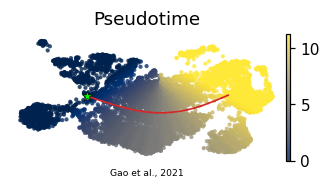

In [ ]:
F = adata.uns['graph']['F'].T
G = nx.from_numpy_array((B>0).astype(int))
# rotate node coords into the linear frame the same way as the cells
xy0 = adata.obsm['X_umap']; cc = xy0 - xy0.mean(0)
_,_,vt2 = np.linalg.svd(cc, full_matrices=False)
th2 = np.arctan2(vt2[0,1], vt2[0,0])
Rm = np.array([[np.cos(-th2),-np.sin(-th2)],[np.sin(-th2),np.cos(-th2)]])
Fr = (F - xy0.mean(0)) @ Rm.T
flip = np.sign(np.corrcoef(cc @ Rm.T[:, :1].ravel() if False else (cc@Rm.T)[:,0], t)[0,1])
# align node x-flip to the stored X_umap_lin (recompute sign from cells)
signx = 1 if np.corrcoef((cc@Rm.T)[:,0], adata.obsm['X_umap_lin'][:,0])[0,1] > 0 else -1
Fr[:,0] *= signx
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
for e in G.edges():
    ax.plot(Fr[list(e),0], Fr[list(e),1], color='#d62728', lw=1.1, zorder=5)
ax.scatter(Fr[root,0], Fr[root,1], c='lime', s=45, marker='*', edgecolor='k', lw=.4, zorder=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Gao et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
plt.show()
print('saved manifold.h5ad + manifold.pdf | root tip', root)